## Table of Contents

1. [Imports](#Imports)
2. [Dataset Column Description](#Dataset-Column-Description)
3. [Data Loading](#Data-Loading)
4. [Table Overview](#Table-Overview)
5. [Target Distribution](#Target-Distribution)
6. [Missing Values](#Missing-Values)
7. [Numerical Features and Anomalies](#Numerical-Features-and-Anomalies)
8. [Categorical Features and Target](#Categorical-Features-and-Target)
9. [Feature Correlations](#Feature-Correlations)
10. [Temporal and Demand Dynamics](#Temporal-and-Demand-Dynamics)
11. [EDA Conclusion](#EDA-Conclusion)


In [61]:
%reload_ext autoreload
%autoreload 2

# Imports

In [62]:
import pandas as pd
import os
import kagglehub

## Dataset Column Description

| Столбец | Тип | Описание |
|---|---|---|
| **Date** | str (date) | Дата наблюдения в формате `DD/MM/YYYY` |
| **Rented Bike Count** | int | Количество арендованных велосипедов за час — **целевая переменная** |
| **Hour** | int | Час суток (0–23) |
| **Temperature(°C)** | float | Температура воздуха в градусах Цельсия |
| **Humidity(%)** | int | Влажность воздуха, % |
| **Wind speed (m/s)** | float | Скорость ветра, м/с |
| **Visibility (10m)** | int | Видимость в единицах по 10 м (т.е. 2000 = 20 км) |
| **Dew point temperature(°C)** | float | Точка росы, °C |
| **Solar Radiation (MJ/m²)** | float | Солнечная радиация, МДж/м² |
| **Rainfall(mm)** | float | Количество осадков в виде дождя, мм |
| **Snowfall (cm)** | float | Количество осадков в виде снега, см |
| **Seasons** | str | Время года: `Winter`, `Spring`, `Summer`, `Autumn` |
| **Holiday** | str | `Holiday` / `No holiday` — праздничный день или нет |
| **Functioning Day** | str | `Yes` / `No` — работал ли прокат в этот час (`NoFunc` = нерабочие часы) |

## Data Loading

In [63]:
path = kagglehub.dataset_download("joebeachcapital/seoul-bike-sharing")

print("Path to dataset files:", path)

Path to dataset files: /home/alexandr/.cache/kagglehub/datasets/joebeachcapital/seoul-bike-sharing/versions/1


In [64]:
file_path = os.path.join(path, "SeoulBikeData.csv")
df = pd.read_csv(file_path, encoding="unicode_escape")

## Table Overview

In [65]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [67]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
print("Новые названия колонок:")
print(df.columns.tolist())

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

cat_cols = ['seasons', 'holiday', 'functioning_day']
df[cat_cols] = df[cat_cols].astype('category')

df.info()

Новые названия колонок:
['date', 'rented_bike_count', 'hour', 'temperature°c', 'humidity%', 'wind_speed_m/s', 'visibility_10m', 'dew_point_temperature°c', 'solar_radiation_mj/m2', 'rainfallmm', 'snowfall_cm', 'seasons', 'holiday', 'functioning_day']
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   date                     8760 non-null   datetime64[us]
 1   rented_bike_count        8760 non-null   int64         
 2   hour                     8760 non-null   int64         
 3   temperature°c            8760 non-null   float64       
 4   humidity%                8760 non-null   int64         
 5   wind_speed_m/s           8760 non-null   float64       
 6   visibility_10m           8760 non-null   int64         
 7   dew_point_temperature°c  8760 non-null   float64       
 8   solar_radiation_mj/m2    8760 non-null 

## Target Distribution

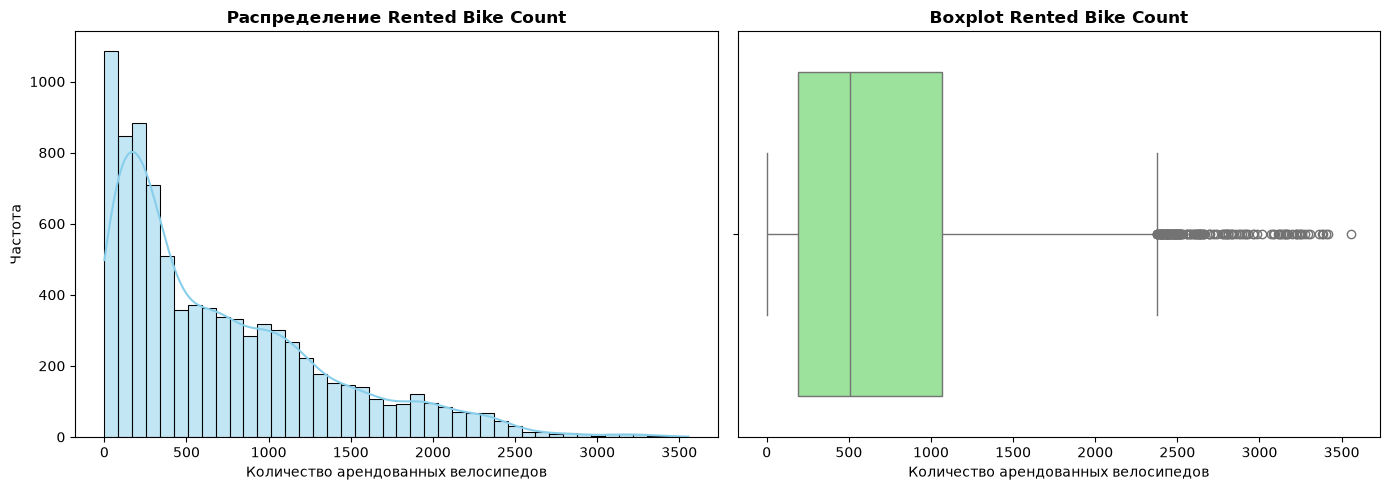

Количество часов с нулевой арендой: 295 (3.37%)


In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['rented_bike_count'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение Rented Bike Count', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Количество арендованных велосипедов')
axes[0].set_ylabel('Частота')

sns.boxplot(x=df['rented_bike_count'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot Rented Bike Count', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Количество арендованных велосипедов')

plt.tight_layout()
plt.show()

zero_rents = (df['rented_bike_count'] == 0).sum()
print(f"Количество часов с нулевой арендой: {zero_rents} ({zero_rents / len(df) * 100:.2f}%)")

In [69]:
import numpy as np

target = df['rented_bike_count']

print("=" * 60)
print("TARGET VARIABLE SUMMARY: Rented Bike Count")
print("=" * 60)

print(f"Всего наблюдений:      {len(target):,}")
print(f"Среднее:               {target.mean():.2f}")
print(f"Медиана:               {target.median():.2f}")
print(f"Std:                   {target.std():.2f}")
print(f"Min / Max:             {target.min()} / {target.max()}")
print(f"Skewness:              {target.skew():.2f}")
print(f"Kurtosis:              {target.kurt():.2f}")

print("\nКвантили:")
for q in [0.25, 0.5, 0.75, 0.90, 0.95, 0.99]:
    print(f"  {int(q*100):>3}%: {target.quantile(q):.0f}")

print("\n" + "-" * 60)
print("НУЛЕВЫЕ ЗНАЧЕНИЯ")
print("-" * 60)
zero_mask = target == 0
zero_cnt = zero_mask.sum()
print(f"Нулей всего:           {zero_cnt:,} ({zero_cnt / len(target) * 100:.2f}%)")

if 'functioning_day' in df.columns:
    zeros_non_func = df.loc[df['functioning_day'] == 'No', 'rented_bike_count'].eq(0).sum()
    zeros_func     = df.loc[df['functioning_day'] == 'Yes', 'rented_bike_count'].eq(0).sum()
    print(f"  из них Functioning Day = No:  {zeros_non_func:,}")
    print(f"  из них Functioning Day = Yes: {zeros_func:,}")
    if zeros_non_func == zero_cnt:
        print("  → Все нули объясняются нерабочими часами (не выбросы)")

print("\n" + "-" * 60)
print("ПРОВЕРКА НА АНОМАЛИИ (IQR)")
print("-" * 60)
q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = ((target < lower) | (target > upper)).sum()
print(f"IQR:                   {iqr:.2f}")
print(f"Границы (1.5×IQR):     [{lower:.1f}; {upper:.1f}]")
print(f"Выбросов по правилу:   {outliers:,} ({outliers / len(target) * 100:.2f}%)")
print("=" * 60)

TARGET VARIABLE SUMMARY: Rented Bike Count
Всего наблюдений:      8,760
Среднее:               704.60
Медиана:               504.50
Std:                   645.00
Min / Max:             0 / 3556
Skewness:              1.15
Kurtosis:              0.85

Квантили:
   25%: 191
   50%: 504
   75%: 1065
   90%: 1671
   95%: 2043
   99%: 2526

------------------------------------------------------------
НУЛЕВЫЕ ЗНАЧЕНИЯ
------------------------------------------------------------
Нулей всего:           295 (3.37%)
  из них Functioning Day = No:  295
  из них Functioning Day = Yes: 0
  → Все нули объясняются нерабочими часами (не выбросы)

------------------------------------------------------------
ПРОВЕРКА НА АНОМАЛИИ (IQR)
------------------------------------------------------------
IQR:                   874.25
Границы (1.5×IQR):     [-1120.4; 2376.6]
Выбросов по правилу:   158 (1.80%)


## Missing Values

In [70]:
missing_values = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

pd.DataFrame({'Пропуски (шт)': missing_values, 'Пропуски (%)': missing_percent})

,Пропуски (шт),Пропуски (%)
date,0,0.0
rented_bike_count,0,0.0
hour,0,0.0
temperature°c,0,0.0
humidity%,0,0.0
wind_speed_m/s,0,0.0
visibility_10m,0,0.0
dew_point_temperature°c,0,0.0
solar_radiation_mj/m2,0,0.0
rainfallmm,0,0.0


In [71]:
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates}")

time_duplicates = df.duplicated(subset=['date', 'hour']).sum()
print(f"Дубликатов по связке (date + hour): {time_duplicates}")

Полных дубликатов: 0
Дубликатов по связке (date + hour): 0


In [72]:
display(df.describe().T)

display(df.describe(include=['category', 'object']).T)

,count,mean,min,25%,50%,75%,max,std
date,8760,2018-06-01 00:00:00,2017-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
rented_bike_count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
temperature°c,8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
humidity%,8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
wind_speed_m/s,8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
visibility_10m,8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
dew_point_temperature°c,8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
solar_radiation_mj/m2,8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
rainfallmm,8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193


,count,unique,top,freq
seasons,8760,4,Spring,2208
holiday,8760,2,No Holiday,8328
functioning_day,8760,2,Yes,8465


## Numerical Features and Anomalies



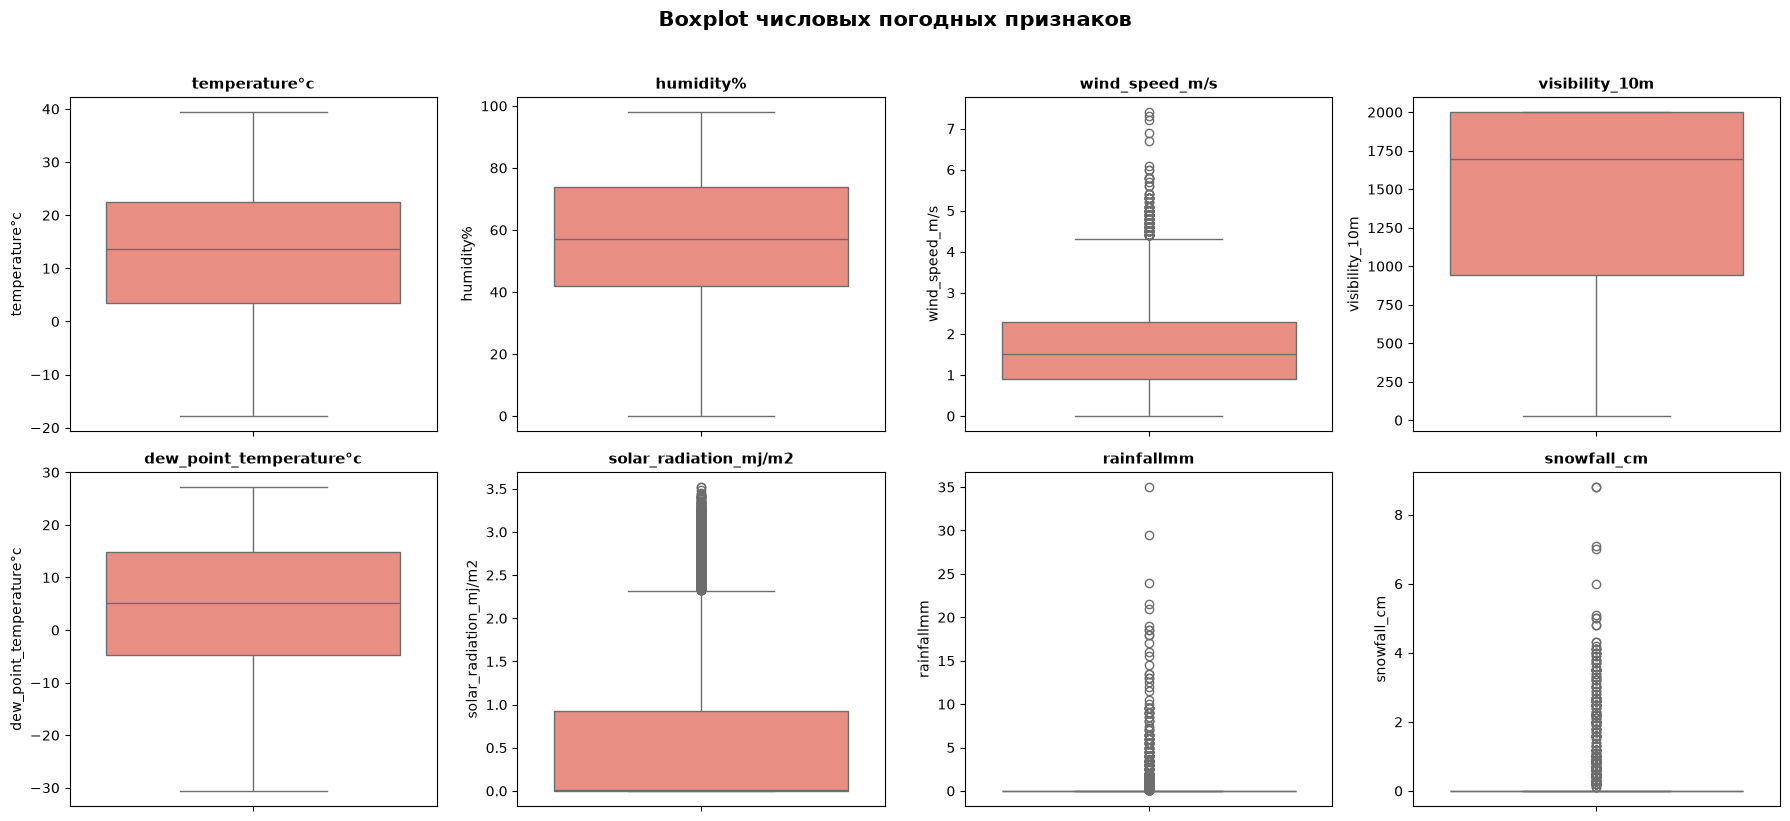

In [73]:
num_cols = [
    'temperature°c', 'humidity%', 'wind_speed_m/s', 'visibility_10m',
    'dew_point_temperature°c', 'solar_radiation_mj/m2', 'rainfallmm', 'snowfall_cm'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col, fontsize=11, fontweight='bold')

plt.suptitle('Boxplot числовых погодных признаков', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [74]:
import numpy as np

num_cols = [
    'temperature°c', 'humidity%', 'wind_speed_m/s', 'visibility_10m',
    'dew_point_temperature°c', 'solar_radiation_mj/m2', 'rainfallmm', 'snowfall_cm'
]

print("=" * 90)
print("NUMERICAL WEATHER FEATURES — SUMMARY & OUTLIERS (IQR rule)")
print("=" * 90)

for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((s < lower) | (s > upper)).sum()
    n_zeros = (s == 0).sum()

    print(f"\n▶ {col}")
    print(f"   n = {len(s):,}  |  mean = {s.mean():.2f}  |  median = {s.median():.2f}  |  std = {s.std():.2f}")
    print(f"   min / max = {s.min():.2f} / {s.max():.2f}")
    print(f"   Q1 / Q3   = {q1:.2f} / {q3:.2f}  |  IQR = {iqr:.2f}")
    print(f"   whiskers  = [{lower:.2f}; {upper:.2f}]")
    print(f"   outliers  = {outliers:,} ({outliers / len(s) * 100:.2f}%)")
    print(f"   zeros     = {n_zeros:,} ({n_zeros / len(s) * 100:.2f}%)")
    print(f"   skew      = {s.skew():.2f}  |  kurt = {s.kurt():.2f}")

print("\n" + "=" * 90)
print("КОРОТКИЙ ИТОГ ПО ВЫБРОСАМ (только те признаки, где есть > 0)")
print("=" * 90)
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    if outliers > 0:
        print(f"  {col:<30} {outliers:>5} ({outliers / len(s) * 100:>5.2f}%)")

NUMERICAL WEATHER FEATURES — SUMMARY & OUTLIERS (IQR rule)

▶ temperature°c
   n = 8,760  |  mean = 12.88  |  median = 13.70  |  std = 11.94
   min / max = -17.80 / 39.40
   Q1 / Q3   = 3.50 / 22.50  |  IQR = 19.00
   whiskers  = [-25.00; 51.00]
   outliers  = 0 (0.00%)
   zeros     = 21 (0.24%)
   skew      = -0.20  |  kurt = -0.84

▶ humidity%
   n = 8,760  |  mean = 58.23  |  median = 57.00  |  std = 20.36
   min / max = 0.00 / 98.00
   Q1 / Q3   = 42.00 / 74.00  |  IQR = 32.00
   whiskers  = [-6.00; 122.00]
   outliers  = 0 (0.00%)
   zeros     = 17 (0.19%)
   skew      = 0.06  |  kurt = -0.80

▶ wind_speed_m/s
   n = 8,760  |  mean = 1.72  |  median = 1.50  |  std = 1.04
   min / max = 0.00 / 7.40
   Q1 / Q3   = 0.90 / 2.30  |  IQR = 1.40
   whiskers  = [-1.20; 4.40]
   outliers  = 161 (1.84%)
   zeros     = 74 (0.84%)
   skew      = 0.89  |  kurt = 0.73

▶ visibility_10m
   n = 8,760  |  mean = 1436.83  |  median = 1698.00  |  std = 608.30
   min / max = 27.00 / 2000.00
   Q1 / Q

## Categorical Features and Target



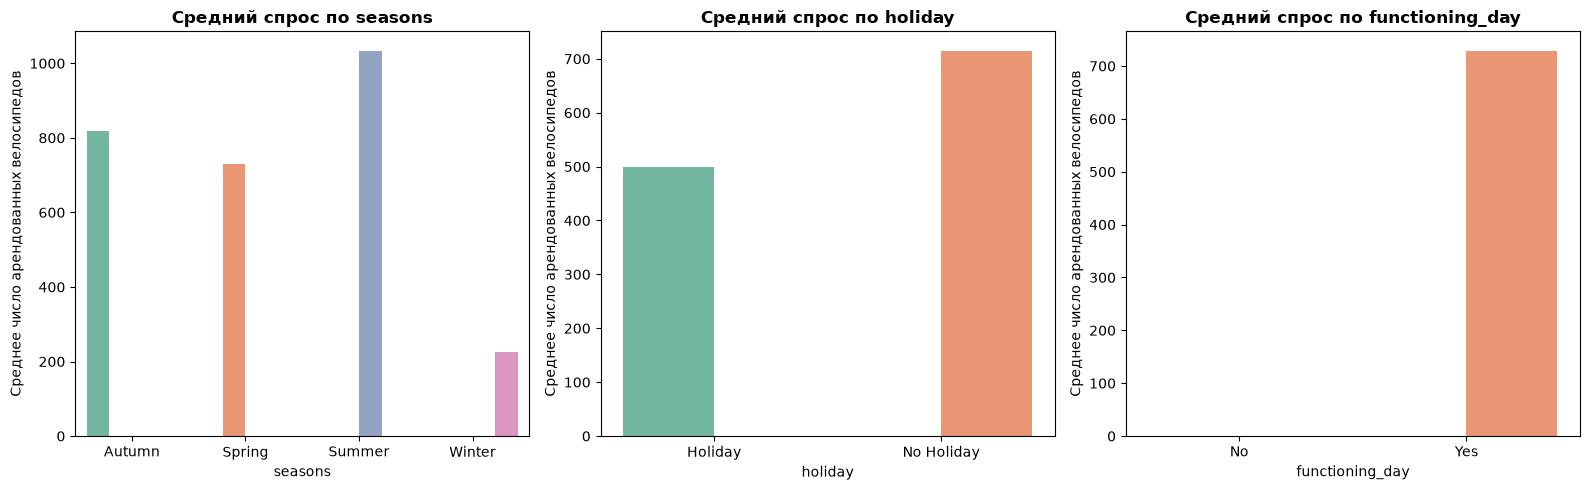

Средняя аренда в нерабочие часы (functioning_day == 'No'): 0.0


In [75]:
cat_cols = ['seasons', 'holiday', 'functioning_day']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(cat_cols):
    sns.barplot(
        x=col, y='rented_bike_count', data=df, ax=axes[i],
        hue=col, palette='Set2', legend=False, errorbar=None
    )
    axes[i].set_title(f'Средний спрос по {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Среднее число арендованных велосипедов')

plt.tight_layout()
plt.show()

print("Средняя аренда в нерабочие часы (functioning_day == 'No'):",
      df[df['functioning_day'] == 'No']['rented_bike_count'].mean())

In [76]:
cat_cols = ['seasons', 'holiday', 'functioning_day']

print("=" * 70)
print("CATEGORICAL FEATURES vs TARGET (Rented Bike Count)")
print("=" * 70)

for col in cat_cols:
    print(f"\n▶ {col}")
    stats = (
        df.groupby(col)['rented_bike_count']
          .agg(['count', 'mean', 'median', 'std'])
          .round(2)
    )
    stats.columns = ['n', 'mean', 'median', 'std']
    stats['%_of_total'] = (stats['n'] / len(df) * 100).round(2)
    print(stats.to_string())

print("\n" + "=" * 70)
print("ВАЖНАЯ ПРОВЕРКА: аренда в нерабочие часы (functioning_day == 'No')")
print("=" * 70)
non_func = df[df['functioning_day'] == 'No']['rented_bike_count']
func     = df[df['functioning_day'] == 'Yes']['rented_bike_count']

print(f"Functioning Day = No:  n = {len(non_func):>5}  |  "
      f"mean = {non_func.mean():.2f}  |  median = {non_func.median():.2f}  |  "
      f"max = {non_func.max():.0f}  |  zeros = {(non_func == 0).sum()}")
print(f"Functioning Day = Yes: n = {len(func):>5}  |  "
      f"mean = {func.mean():.2f}  |  median = {func.median():.2f}  |  "
      f"max = {func.max():.0f}  |  zeros = {(func == 0).sum()}")

if non_func.max() == 0:
    print("\n→ В нерабочие часы аренда ВСЕГДА 0. Это правило, а не выброс.")
    print("  Рекомендация: исключить эти строки из обучения модели")
    print("  или обрабатывать отдельной логикой.")

CATEGORICAL FEATURES vs TARGET (Rented Bike Count)

▶ seasons
            n     mean  median     std  %_of_total
seasons                                           
Autumn   2184   819.60   763.5  651.09       24.93
Spring   2208   730.03   583.0  621.51       25.21
Summer   2208  1034.07   905.5  690.24       25.21
Winter   2160   225.54   203.0  150.37       24.66

▶ holiday
               n    mean  median     std  %_of_total
holiday                                             
Holiday      432  499.76   240.0  570.77        4.93
No Holiday  8328  715.23   524.5  646.88       95.07

▶ functioning_day
                    n    mean  median     std  %_of_total
functioning_day                                          
No                295    0.00     0.0    0.00        3.37
Yes              8465  729.16   542.0  642.35       96.63

ВАЖНАЯ ПРОВЕРКА: аренда в нерабочие часы (functioning_day == 'No')
Functioning Day = No:  n =   295  |  mean = 0.00  |  median = 0.00  |  max = 0  |  zeros =

## Feature Correlations


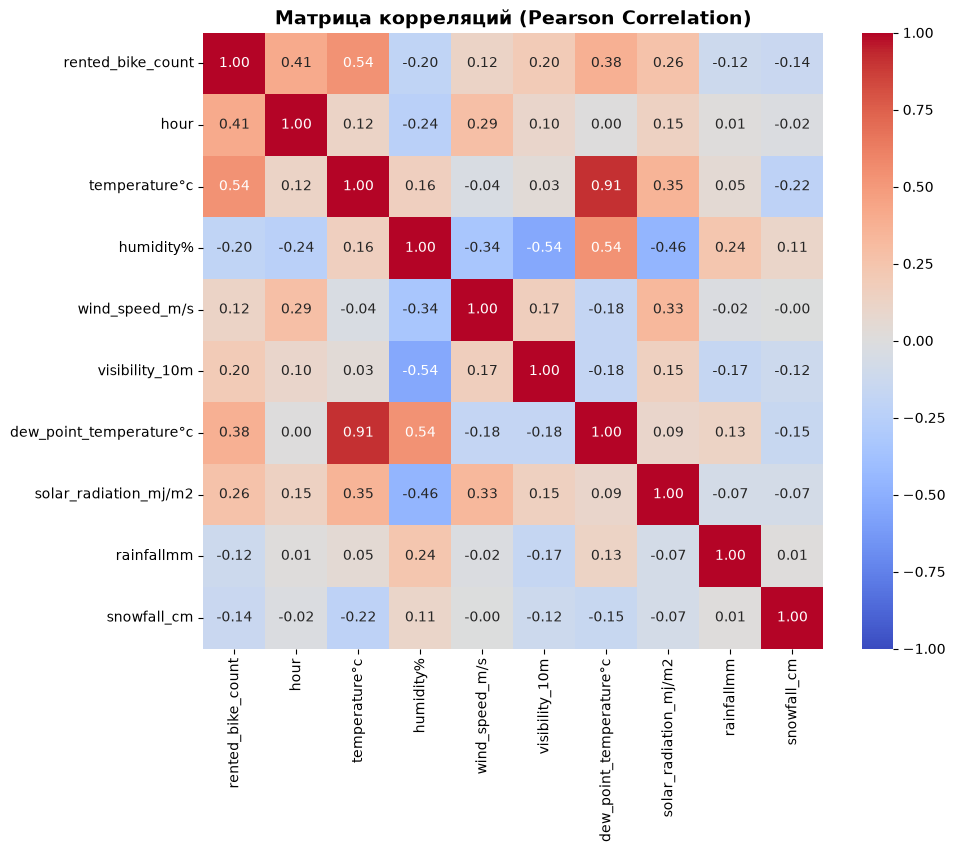

In [77]:
plt.figure(figsize=(10, 8))

corr = df.select_dtypes(include=['float64', 'int64']).corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляций (Pearson Correlation)', fontsize=14, fontweight='bold')
plt.show()

In [78]:
corr 

,rented_bike_count,hour,temperature°c,humidity%,wind_speed_m/s,visibility_10m,dew_point_temperature°c,solar_radiation_mj/m2,rainfallmm,snowfall_cm
rented_bike_count,1.000000,0.410257,0.538558,-0.199780,0.121108,0.199280,0.379788,0.261837,-0.123074,-0.141804
hour,0.410257,1.000000,0.124114,-0.241644,0.285197,0.098753,0.003054,0.145131,0.008715,-0.021516
temperature°c,0.538558,0.124114,1.000000,0.159371,-0.036252,0.034794,0.912798,0.353505,0.050282,-0.218405
humidity%,-0.199780,-0.241644,0.159371,1.000000,-0.336683,-0.543090,0.536894,-0.461919,0.236397,0.108183
wind_speed_m/s,0.121108,0.285197,-0.036252,-0.336683,1.000000,0.171507,-0.176486,0.332274,-0.019674,-0.003554
visibility_10m,0.199280,0.098753,0.034794,-0.543090,0.171507,1.000000,-0.176630,0.149738,-0.167629,-0.121695
dew_point_temperature°c,0.379788,0.003054,0.912798,0.536894,-0.176486,-0.176630,1.000000,0.094381,0.125597,-0.150887
solar_radiation_mj/m2,0.261837,0.145131,0.353505,-0.461919,0.332274,0.149738,0.094381,1.000000,-0.074290,-0.072301
rainfallmm,-0.123074,0.008715,0.050282,0.236397,-0.019674,-0.167629,0.125597,-0.074290,1.000000,0.008500
snowfall_cm,-0.141804,-0.021516,-0.218405,0.108183,-0.003554,-0.121695,-0.150887,-0.072301,0.008500,1.000000



## Temporal and Demand Dynamics



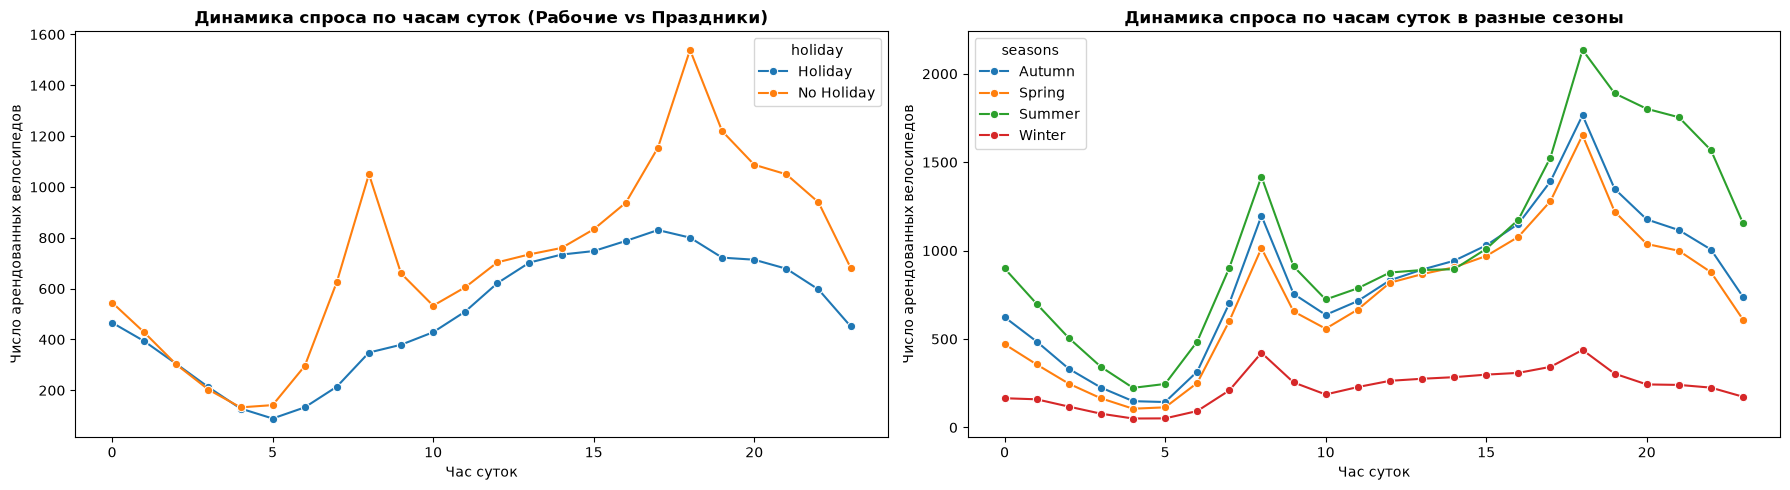

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.lineplot(
    x='hour', y='rented_bike_count', hue='holiday', data=df,
    ax=axes[0], errorbar=None, marker='o'
)
axes[0].set_title('Динамика спроса по часам суток (Рабочие vs Праздники)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Число арендованных велосипедов')

sns.lineplot(
    x='hour', y='rented_bike_count', hue='seasons', data=df,
    ax=axes[1], errorbar=None, marker='o'
)
axes[1].set_title('Динамика спроса по часам суток в разные сезоны',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Час суток')
axes[1].set_ylabel('Число арендованных велосипедов')

plt.tight_layout()
plt.show()

In [80]:
import pandas as pd

print("=" * 80)
print("AVERAGE RENTED BIKE COUNT BY HOUR")
print("=" * 80)

print("\n▶ Overall by hour (0–23):")
overall = df.groupby('hour')['rented_bike_count'].mean().round(1)
print(overall.to_string())

print("\n▶ By hour: Holiday vs No Holiday (mean):")
by_holiday = df.pivot_table(
    index='hour', columns='holiday',
    values='rented_bike_count', aggfunc='mean'
).round(1)
print(by_holiday.to_string())

print("\n▶ By hour: Seasons (mean):")
by_season = df.pivot_table(
    index='hour', columns='seasons',
    values='rented_bike_count', aggfunc='mean'
).round(1)
print(by_season.to_string())

print("\n" + "=" * 80)
print("PEAK / LOW HOURS BY HOLIDAY")
print("=" * 80)

for label, subset in df.groupby('holiday'):
    grp = subset.groupby('hour')['rented_bike_count'].mean().dropna()

    if len(grp) == 0:
        print(f"  {label:<15} → нет данных")
        continue

    peak_h = grp.idxmax()
    low_h  = grp.idxmin()
    print(f"  {label:<15} peak hour = {peak_h:>2} ({grp.max():.1f})  |  "
          f"low hour = {low_h:>2} ({grp.min():.1f})")

AVERAGE RENTED BIKE COUNT BY HOUR

▶ Overall by hour (0–23):
hour
0      541.5
1      426.2
2      301.6
3      203.3
4      132.6
5      139.1
6      287.6
7      606.0
8     1015.7
9      646.0
10     527.8
11     600.9
12     699.4
13     733.2
14     758.8
15     829.2
16     930.6
17    1138.5
18    1502.9
19    1195.1
20    1069.0
21    1031.4
22     922.8
23     671.1

▶ By hour: Holiday vs No Holiday (mean):
holiday  Holiday  No Holiday
hour                        
0          466.2       545.4
1          393.3       427.9
2          303.9       301.5
3          212.3       202.9
4          128.4       132.8
5           89.0       141.7
6          132.8       295.6
7          214.3       626.3
8          348.5      1050.3
9          379.2       659.8
10         428.6       533.0
11         510.0       605.6
12         621.6       703.5
13         702.7       734.8
14         734.0       760.1
15         747.8       833.4
16         787.6       938.0
17         830.5      1154.5


In [81]:
print("Уникальные значения holiday:", df['holiday'].unique())
print("\nКоличество по holiday:")
print(df['holiday'].value_counts(dropna=False))
print("\nУникальные значения hour:", sorted(df['hour'].unique())[:5], "...")
print("Пропуски в hour:", df['hour'].isna().sum())

Уникальные значения holiday: ['No Holiday', 'Holiday']
Categories (2, str): ['Holiday', 'No Holiday']

Количество по holiday:
holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

Уникальные значения hour: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] ...
Пропуски в hour: 0


In [82]:
print("=" * 80)
print("PEAK / LOW HOURS BY HOLIDAY")
print("=" * 80)

for label, subset in df.groupby('holiday'):
    grp = subset.groupby('hour')['rented_bike_count'].mean().dropna()

    if len(grp) == 0:
        print(f"  {label:<15} → нет данных")
        continue

    peak_h = grp.idxmax()
    low_h  = grp.idxmin()
    print(f"  {label:<15} peak hour = {peak_h:>2} ({grp.max():.1f})  |  "
          f"low hour = {low_h:>2} ({grp.min():.1f})")

PEAK / LOW HOURS BY HOLIDAY
  Holiday         peak hour = 17 (830.5)  |  low hour =  5 (89.0)
  No Holiday      peak hour = 18 (1539.4)  |  low hour =  4 (132.8)


## EDA Conclusion